# Практика №1. Случайный лес

Задача: классифицировать грибы как съедобные (e) или ядовитые (p) по их физическим характеристикам. Особое внимание уделяется полноте (Recall) по классу ядовитых грибов.

Датасет: UCI Mushroom, 8 124 наблюдения и 22 категориальных признака. В одном из признаков (stalk-root) встречается маркер ?, который трактуется как пропуск. Источник: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/73/mushroom).

Случайный лес объединяет решения множества деревьев. Для категориальных переменных будет использовано One-Hot Encoding.


In [ ]:
%pip install -q ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib

In [ ]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from ucimlrepo import fetch_ucirepo

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Загрузка данных

Загружаем датасет из UCI, проверяем число строк и признаков, а также распределение классов e и p.

In [ ]:
dataset = fetch_ucirepo(id=73)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.iloc[:, 0].copy()

print(f"Размер матрицы признаков: {X_raw.shape}")
print("Целевая переменная:", dataset.data.targets.columns[0])
print("Классы:", pd.Series(y_raw).value_counts().to_dict())
display(X_raw.head())

Размер матрицы признаков: (8124, 22)
Целевая переменная: poisonous
Классы: {'e': 4208, 'p': 3916}


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


## 2. Проверка качества и очистка

В наборе есть категориальный маркер ? для отсутствующего значения. Заменяем его на NaN, проверяем пропуски и дубликаты. Строки с неизвестным целевым классом удаляются, а пропуски признаков заполняются наиболее частой категорией внутри Pipeline. Также отмечаем редкие категории как возможные аномальные наблюдения, но не удаляем их без предметного обоснования.

In [ ]:
df = X_raw.copy()
df["target"] = y_raw.astype("object")
df = df.replace("?", np.nan)

print("Пропуски после преобразования маркера '?' в NaN:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Количество полных дубликатов:", int(df.duplicated().sum()))

rows_before = len(df)
df = df.dropna(subset=["target"]).drop_duplicates().reset_index(drop=True)
print(f"Удалено строк с отсутствующей целью/дубликатов: {rows_before - len(df)}")
X = df.drop(columns="target").astype("object")
y = df["target"].astype(str)

rare_category_report = []
for column in X.columns:
    frequencies = X[column].value_counts(normalize=True, dropna=False)
    rare_count = int((frequencies < 0.01).sum())
    rare_category_report.append({"feature": column, "categories_below_1pct": rare_count})
display(pd.DataFrame(rare_category_report).sort_values("categories_below_1pct", ascending=False))

Пропуски после преобразования маркера '?' в NaN:


,missing
stalk-root,2480
cap-surface,0
cap-shape,0
bruises,0
odor,0
gill-attachment,0
cap-color,0
gill-spacing,0
gill-size,0
gill-color,0


Количество полных дубликатов: 0
Удалено строк с отсутствующей целью/дубликатов: 0


,feature,categories_below_1pct
19,spore-print-color,5
2,cap-color,3
13,stalk-color-above-ring,2
14,stalk-color-below-ring,2
8,gill-color,2
0,cap-shape,2
18,ring-type,2
16,veil-color,1
4,odor,1
1,cap-surface,1


## 3. Разведочный анализ данных (EDA)

Из-за большого числа категориальных признаков построим распределения шести наиболее разнообразных признаков и целевой переменной. Для корреляционной матрицы выполним One-Hot Encoding и отобразим 25 бинарных признаков с наибольшей дисперсией. Это компактный разведочный срез, а не замена анализа всех переменных.

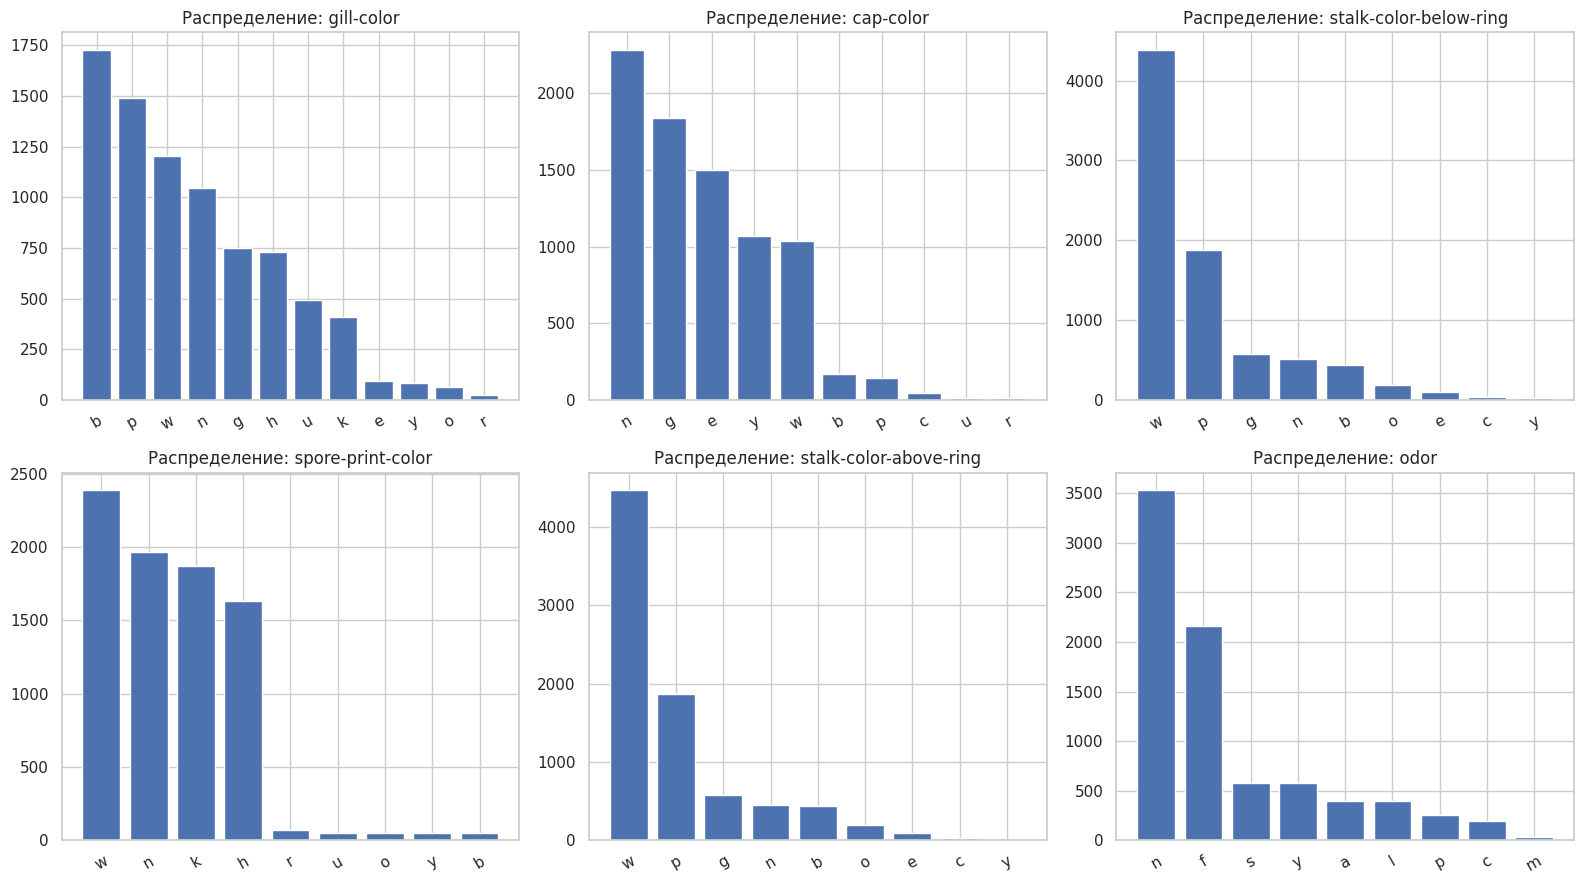

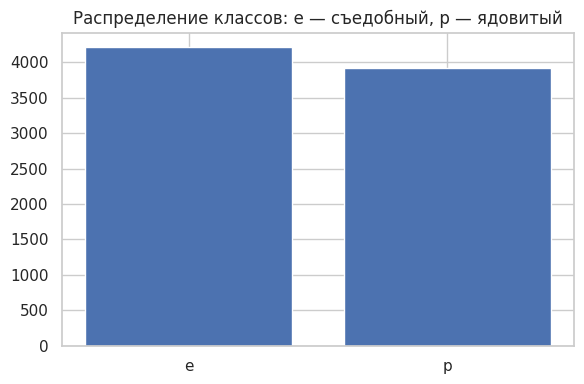

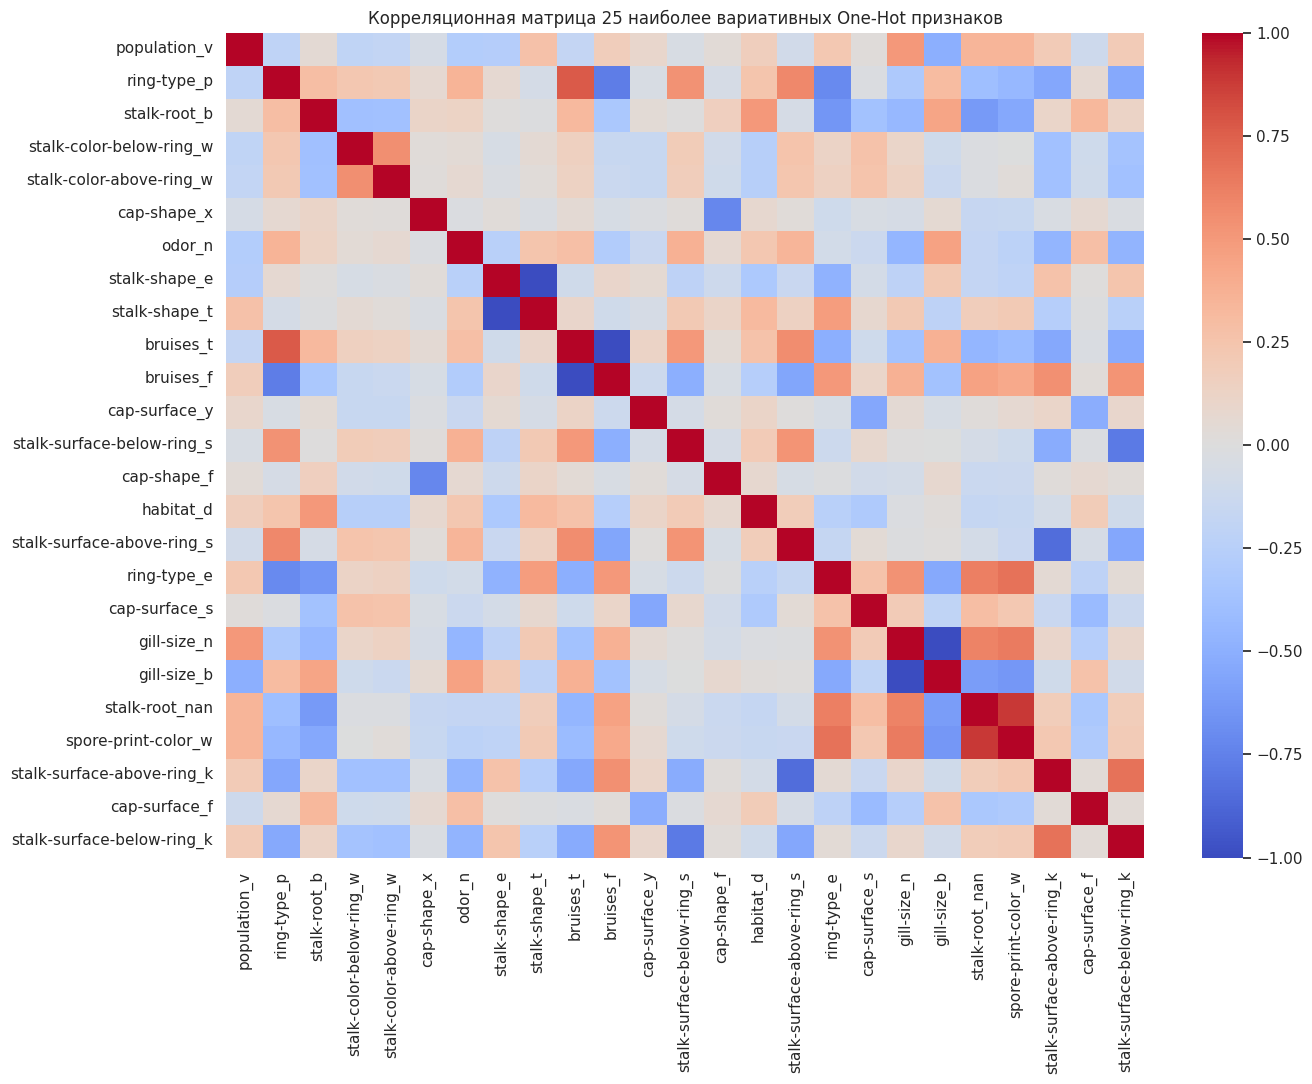

In [ ]:
category_counts = X.nunique().sort_values(ascending=False)
selected_features = category_counts.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for column, ax in zip(selected_features, axes.ravel()):
    counts = X[column].value_counts()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"Распределение: {column}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
class_counts = y.value_counts().reindex(["e", "p"], fill_value=0)
plt.bar(class_counts.index, class_counts.values)
plt.title("Распределение классов: e — съедобный, p — ядовитый")
plt.tight_layout()
plt.show()

encoded_eda = pd.get_dummies(X, dummy_na=True, dtype=int)
top_corr_features = encoded_eda.var().sort_values(ascending=False).head(25).index
correlation_subset = encoded_eda[top_corr_features]
plt.figure(figsize=(14, 11))
sns.heatmap(correlation_subset.corr(), cmap="coolwarm", center=0)
plt.title("Корреляционная матрица 25 наиболее вариативных One-Hot признаков")
plt.tight_layout()
plt.show()

## 4. Разделение выборки и подготовка признаков

Разделяем данные с сохранением долей классов (примерно 70/15/15). Импутация модой и One-Hot Encoding помещены внутрь Pipeline: категории, встреченные только в test, не вызовут ошибку, поскольку используется handle_unknown="ignore".

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")
print("Доли классов в test:")
display(y_test.value_counts(normalize=True).to_frame("share"))

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

Train: 5686, validation: 1219, test: 1219
Доли классов в test:


,share
target,
e,0.518458
p,0.481542


## 5. Подбор параметров случайного леса на validation

По рекомендации лекции ключевой метрикой будет Recall по классу p (ядовитые). Дополнительно посмотрим Macro F1. Сравним несколько настроек глубины деревьев и минимального размера листа. Тестовая часть на этом этапе не используется.

In [ ]:
validation_results = []
best_params = None
best_recall_poisonous = -1.0

for max_depth in [None, 20]:
    for min_samples_leaf in [1, 2]:
        candidate = Pipeline([
            ("preprocessor", categorical_preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=150,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )),
        ])
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_val)
        poisonous_recall = recall_score(y_val, prediction, pos_label="p", zero_division=0)
        macro_f1 = f1_score(y_val, prediction, average="macro")
        validation_results.append({
            "max_depth": max_depth,
            "min_samples_leaf": min_samples_leaf,
            "validation_recall_poisonous": poisonous_recall,
            "validation_macro_f1": macro_f1,
        })
        if poisonous_recall > best_recall_poisonous:
            best_recall_poisonous = poisonous_recall
            best_params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf}

display(pd.DataFrame(validation_results).sort_values(
    ["validation_recall_poisonous", "validation_macro_f1"], ascending=False
))
print("Выбранные параметры:", best_params)

,max_depth,min_samples_leaf,validation_recall_poisonous,validation_macro_f1
0,NaN,1,1.0,1.0
1,NaN,2,1.0,1.0
2,20.0,1,1.0,1.0
3,20.0,2,1.0,1.0


Выбранные параметры: {'max_depth': None, 'min_samples_leaf': 1}


## 6. Финальное обучение и оценка на test

Объединяем train и validation, обучаем итоговый лес и выполняем оценку на test. Главная метрика — Recall для класса p: доля ядовитых образцов, которые модель правильно распознала. Высокий Recall сам по себе не означает отсутствие ошибок, поэтому также анализируем Precision, Accuracy и матрицу ошибок.

,value
Recall poisonous (p),1.0
Precision poisonous (p),1.0
F1 poisonous (p),1.0
Accuracy,1.0
Balanced Accuracy,1.0
Macro F1,1.0


               precision    recall  f1-score   support

   edible (e)       1.00      1.00      1.00       632
poisonous (p)       1.00      1.00      1.00       587

     accuracy                           1.00      1219
    macro avg       1.00      1.00      1.00      1219
 weighted avg       1.00      1.00      1.00      1219



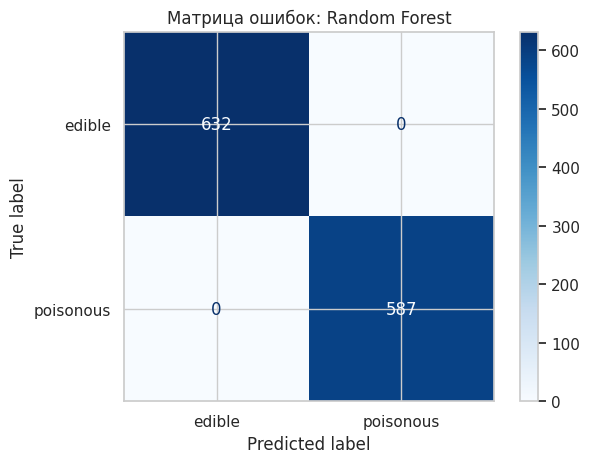

In [ ]:
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_model = Pipeline([
    ("preprocessor", categorical_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        **best_params,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])
final_model.fit(X_train_full, y_train_full)
y_test_pred = final_model.predict(X_test)

test_metrics = {
    "Recall poisonous (p)": recall_score(y_test, y_test_pred, pos_label="p", zero_division=0),
    "Precision poisonous (p)": precision_score(y_test, y_test_pred, pos_label="p", zero_division=0),
    "F1 poisonous (p)": f1_score(y_test, y_test_pred, pos_label="p", zero_division=0),
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Macro F1": f1_score(y_test, y_test_pred, average="macro"),
}
display(pd.Series(test_metrics).to_frame("value"))
print(classification_report(y_test, y_test_pred, labels=["e", "p"], target_names=["edible (e)", "poisonous (p)"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, labels=["e", "p"], display_labels=["edible", "poisonous"], cmap="Blues"
)
plt.title("Матрица ошибок: Random Forest")
plt.tight_layout()
plt.show()

## 7. Важность признаков и сохранение модели

После One-Hot Encoding можно получить важность отдельных бинарных признаков. Она отражает вклад признаков в разбиения деревьев ансамбля и не должна трактоваться как причинность.

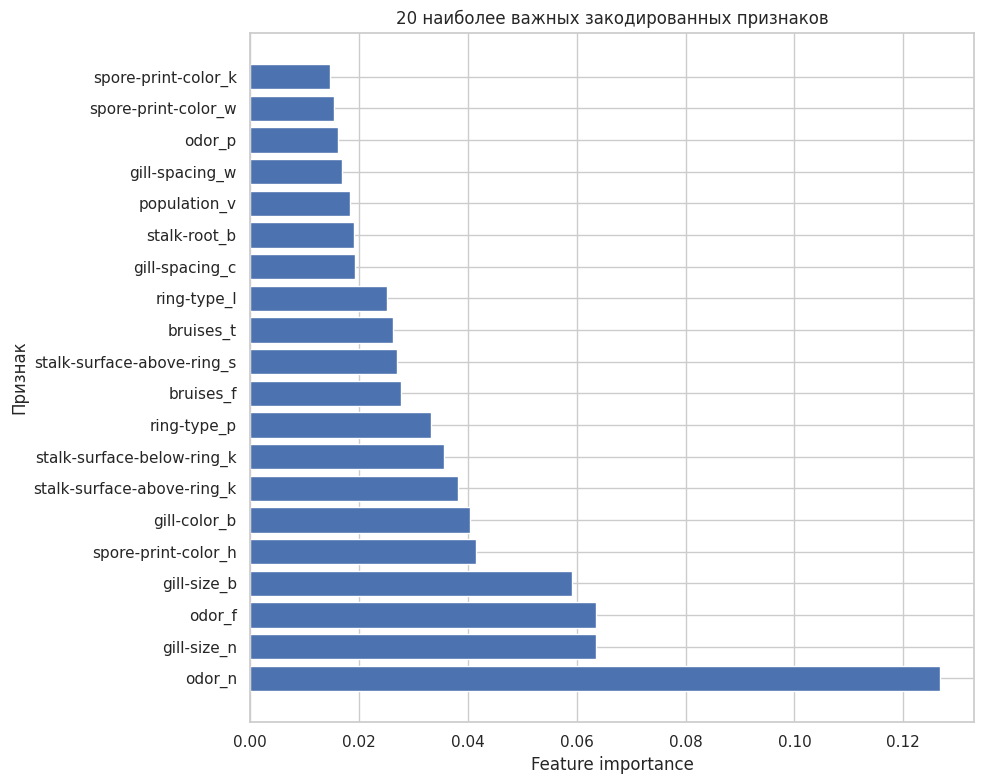

Модель и метрики сохранены в папку artifacts/


In [ ]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
encoded_feature_names = fitted_preprocessor.named_steps["onehot"].get_feature_names_out(X.columns)
importances = final_model.named_steps["model"].feature_importances_
importance_table = pd.Series(importances, index=encoded_feature_names).sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 8))
plt.barh(importance_table.index, importance_table.values)
plt.title("20 наиболее важных закодированных признаков")
plt.xlabel("Feature importance")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, artifact_dir / "random_forest_mushroom.joblib")
with (artifact_dir / "random_forest_metrics.json").open("w", encoding="utf-8") as file:
    json.dump({"best_params": best_params, "validation_recall_poisonous": best_recall_poisonous, "test": test_metrics}, file, ensure_ascii=False, indent=2)
print("Модель и метрики сохранены в папку artifacts/")